## Telco customer churn: IBM dataset

### Sobre o Dataset

**Contexto**: Uma empresa fictícia de telecomunicações que forneceu serviços de telefone fixo e internet para 7043 clientes na Califórnia no terceiro trimestre (Q3).

**Descrição dos Dados**: 7043 observações com 33 variáveis

**Repositório**: [Kaggle](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset)

### Roteiro da Análise

1. Integridade e Sanidade dos Dados
   * Valores ausentes
   * Cardinalidade e tipos de variáveis
2. Diagnóstico do Target (distribuição de classes)
3. Análise Univariada
   * Features numéricas
   * Features categóricas
4. Comentários

### Importação

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.api.types import is_string_dtype

import warnings

plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore")

### 1. Integridade e Sanidade de Dados

In [ ]:
df = pd.read_excel("../data/Telco_customer_churn.xlsx")

df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce").astype(
    "float64"
)

# 0.142% (10 de 7043) da coluna "Total Charges" possui valores nulos, que serão tratados posteriormente

display(df.head(5))
df.info()
df.describe()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,2283.300441,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,2266.771362,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,18.800000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,401.450000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,1397.475000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,3794.737500,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,8684.800000,1.000000,100.000000,6500.000000


### Cardinalidade das Variáveis Categóricas

Country: {'United States'}
State: {'California'}
Gender: {'Male', 'Female'}
Senior Citizen: {'Yes', 'No'}
Partner: {'Yes', 'No'}
Dependents: {'Yes', 'No'}
Phone Service: {'Yes', 'No'}
Multiple Lines: {'Yes', 'No', 'No phone service'}
Internet Service: {'Fiber optic', 'DSL', 'No'}
Online Security: {'Yes', 'No', 'No internet service'}
Online Backup: {'Yes', 'No', 'No internet service'}
Device Protection: {'Yes', 'No', 'No internet service'}
Tech Support: {'Yes', 'No', 'No internet service'}
Streaming TV: {'Yes', 'No', 'No internet service'}
Streaming Movies: {'Yes', 'No', 'No internet service'}
Contract: {'One year', 'Month-to-month', 'Two year'}
Paperless Billing: {'Yes', 'No'}
Payment Method: {'Bank transfer (automatic)', 'Credit card (automatic)', 'Mailed check', 'Electronic check'}
Churn Label: {'Yes', 'No'}
Churn Reason: {"Don't know", 'Network reliability', 'Competitor offered more data', 'Attitude of service provider', 'Competitor had better devices', 'Competitor made better offer

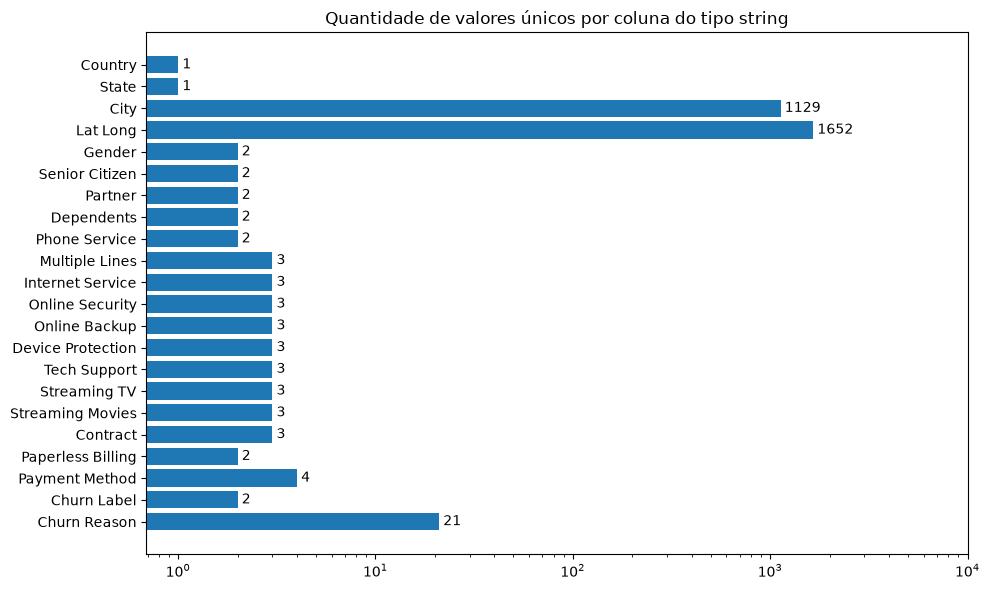

In [3]:
string_columns = [column for column in df.columns if is_string_dtype(df[column])]
string_columns.remove("CustomerID")

unique_counts = [len(df[column].unique()) for column in string_columns]

plt.figure(figsize=(10, 6))
bars = plt.barh(string_columns, unique_counts)
plt.bar_label(bars, labels=[str(count) for count in unique_counts], padding=3)
plt.xscale("log")
plt.title("Quantidade de valores únicos por coluna do tipo string")
plt.xlim([0, 10**4])
plt.gca().invert_yaxis()
plt.tight_layout()

for column in string_columns:
    if column not in ["Lat Long", "City"]:
        print(f"{column}: {set(df[column].values)}")

**Grupos do Churn Reason**

Unknown:
- Don't know

Act of God:
- Deceased
- Moved

Competitor:
- Competitor offered more data
- Competitor made better offer
- Competitor offered higher download speeds
- Competitor had better devices

Cost:
- Lack of affordable download/upload speed
- Price too high
- Extra data charges
- Long distance charges

Service/Product:
- Limited range of services
- Service dissatisfaction
- Product dissatisfaction
- Network reliability

Technical Support:
- Lack of self-service on Website
- Poor expertise of phone support
- Attitude of support person
- Attitude of service providers
- Poor expertise of online support

### 2. Diagnóstico do Target (distribuição de classes)

In [ ]:
churn_values = (
    df.groupby("Churn Label", dropna=False).size().rename("Quantidade").reset_index()
)

churn_values["Percentual"] = (churn_values["Quantidade"] / len(df) * 100).round(2)

# plt.figure()
# plt.bar(churn_values["Churn Label"].astype(str), churn_values["Quantidade"])
# plt.xlabel("Churn Label")
# plt.ylabel("Quantidade de clientes")
# plt.title("Distribuição da variável Churn Label")
# plt.show()

# plt.figure()
# plt.pie(
#     churn_values["Quantidade"],
#     labels=churn_values["Churn Label"].astype(str),
#     autopct="%1.1f%%",
# )
# plt.title("Proporção da variável Churn Label")
# plt.show()

display(churn_values)

,Churn Label,Quantidade,Percentual
0,No,5174,73.46
1,Yes,1869,26.54


### 3. Análise Univariada

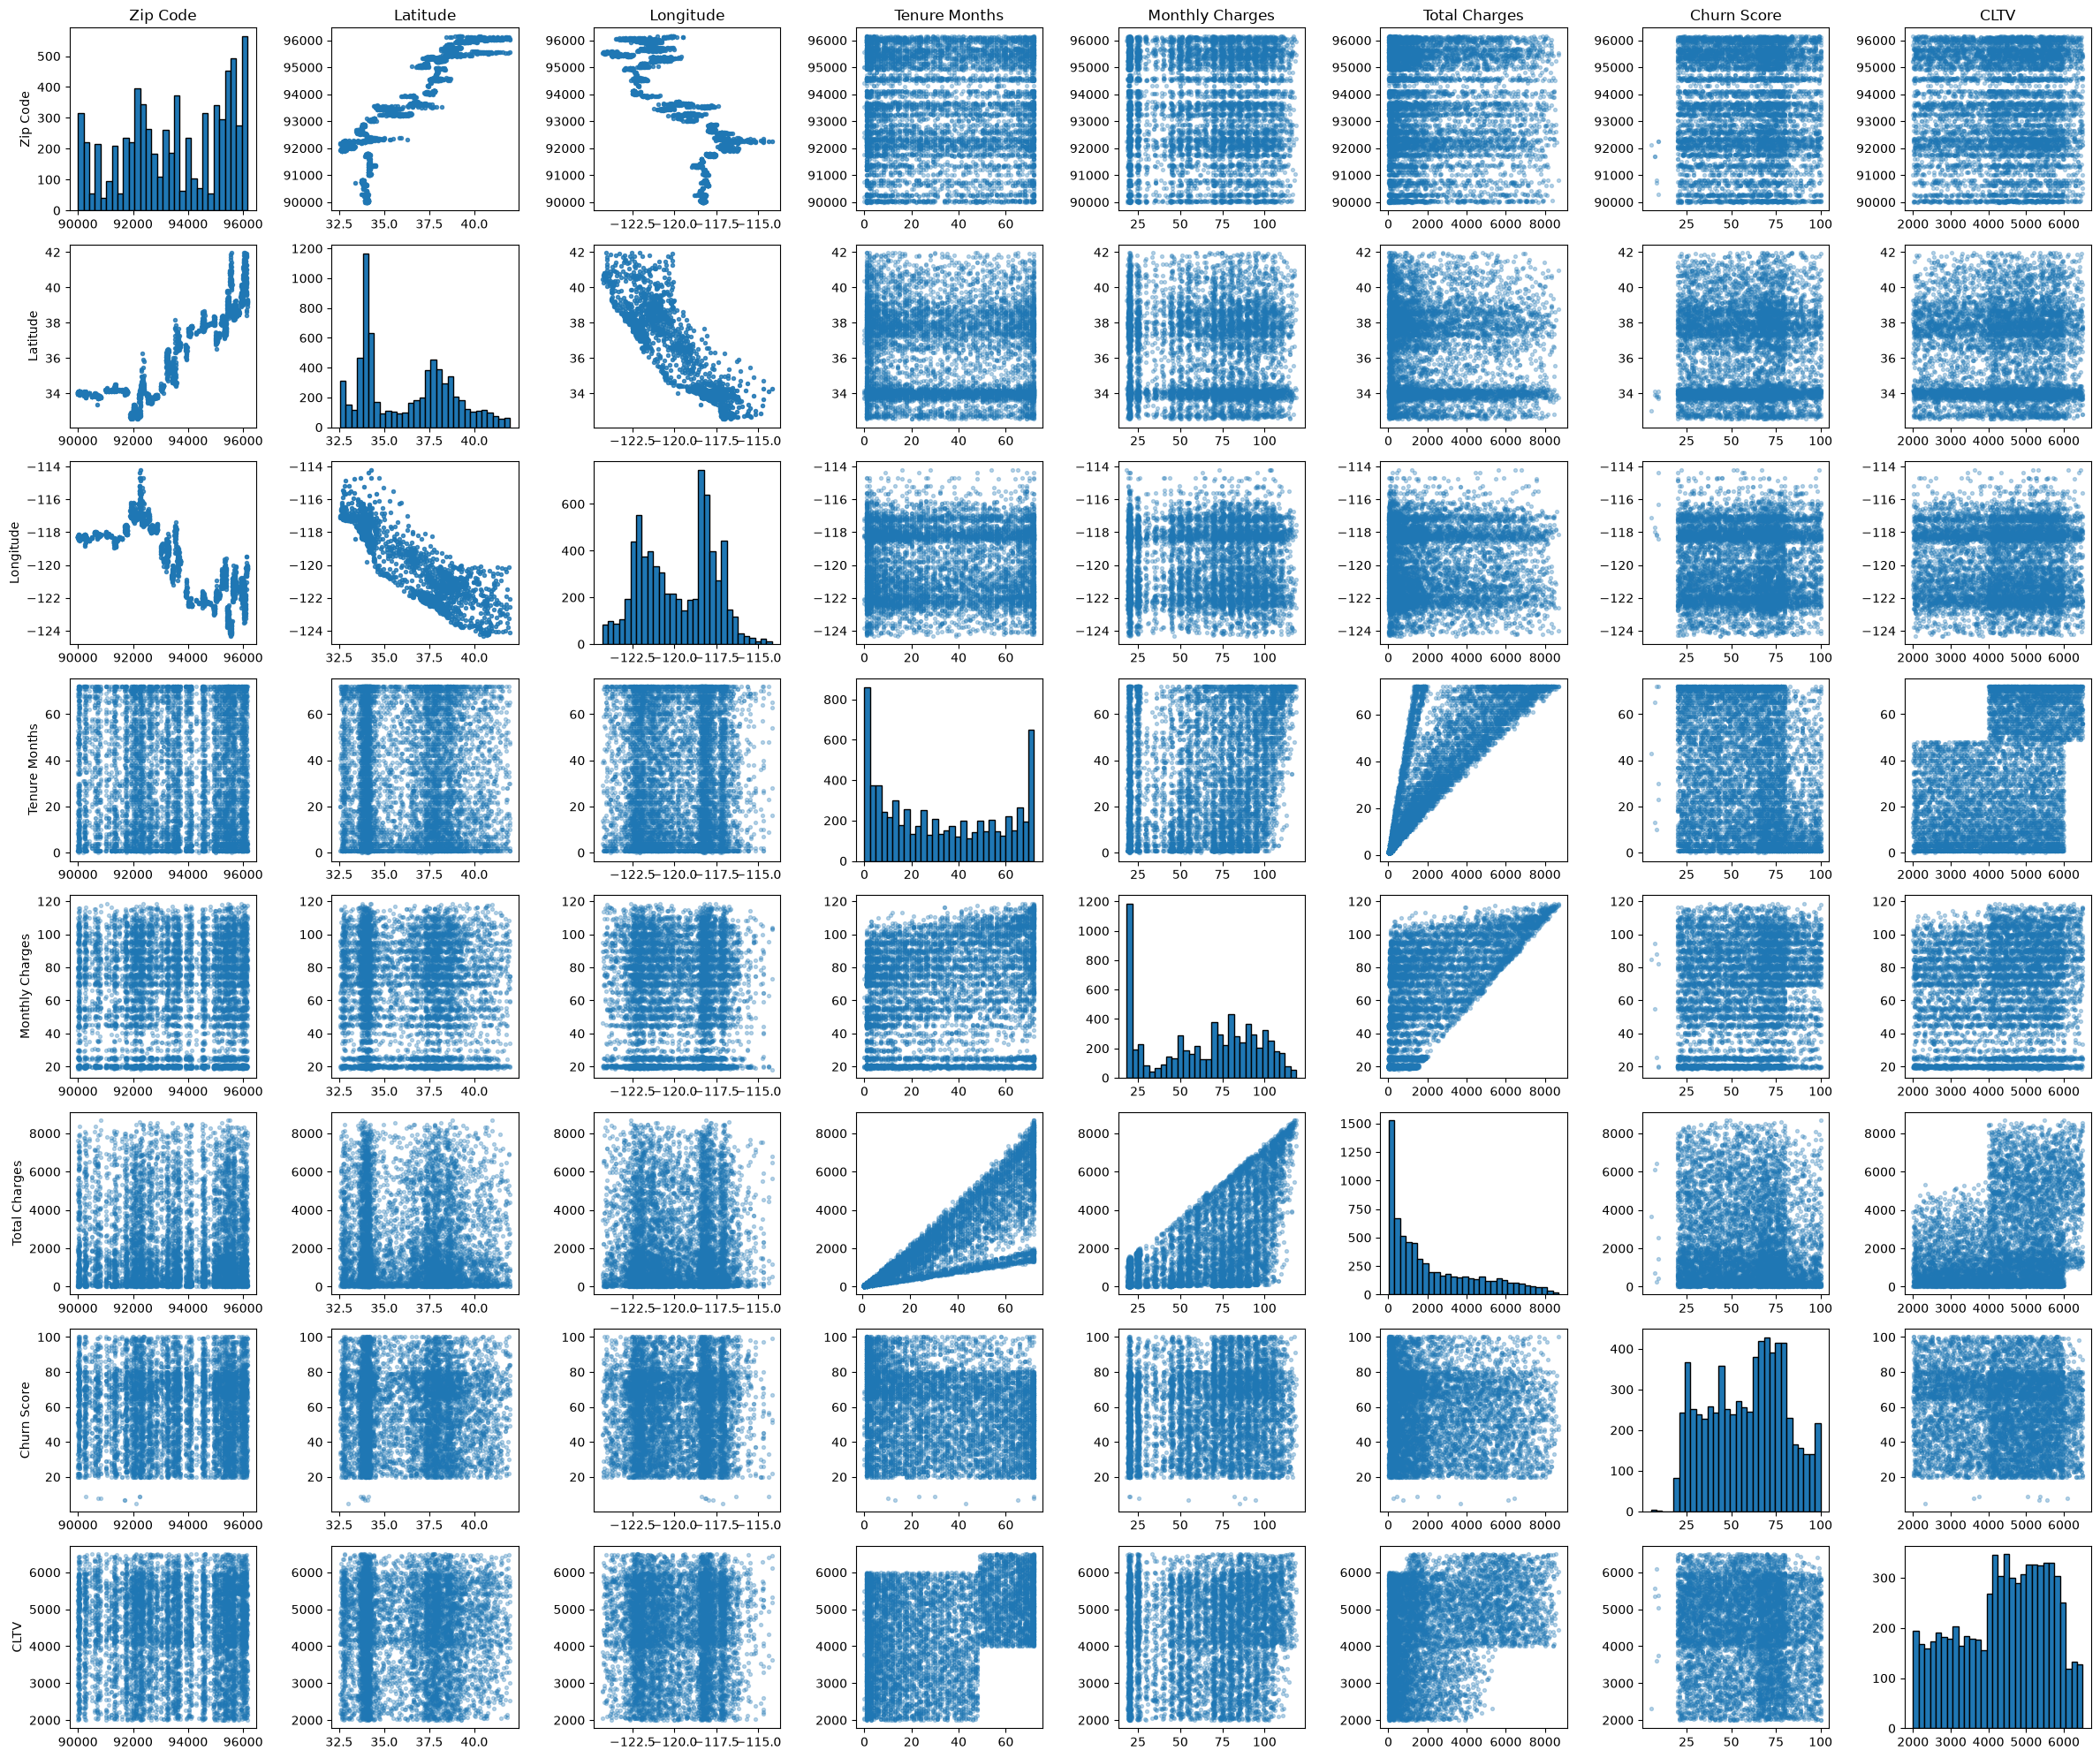

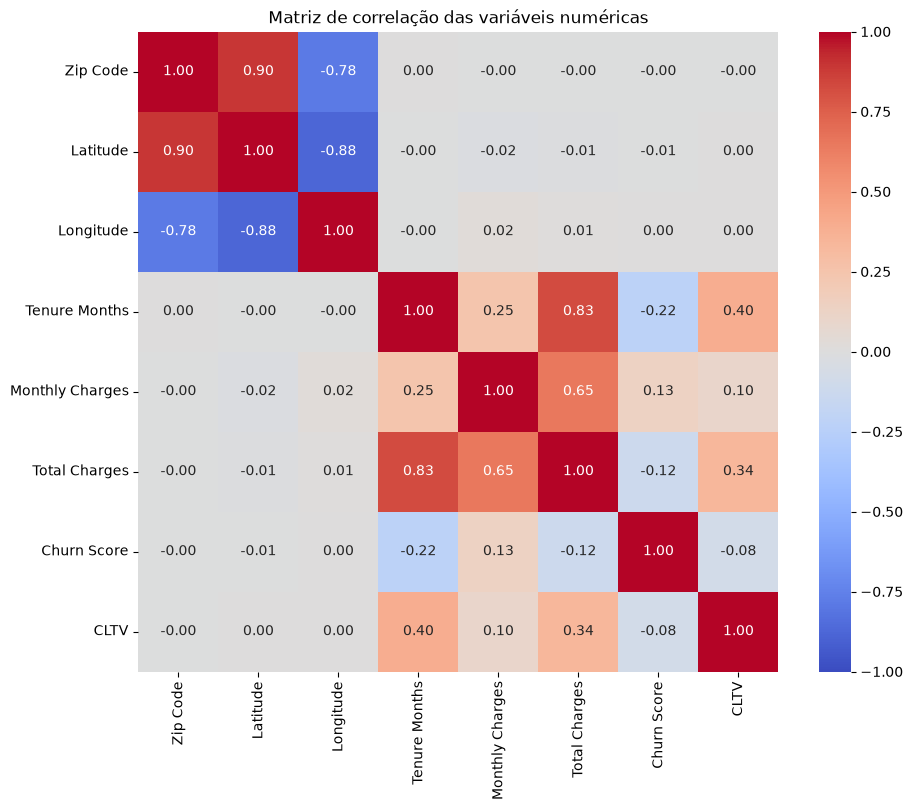

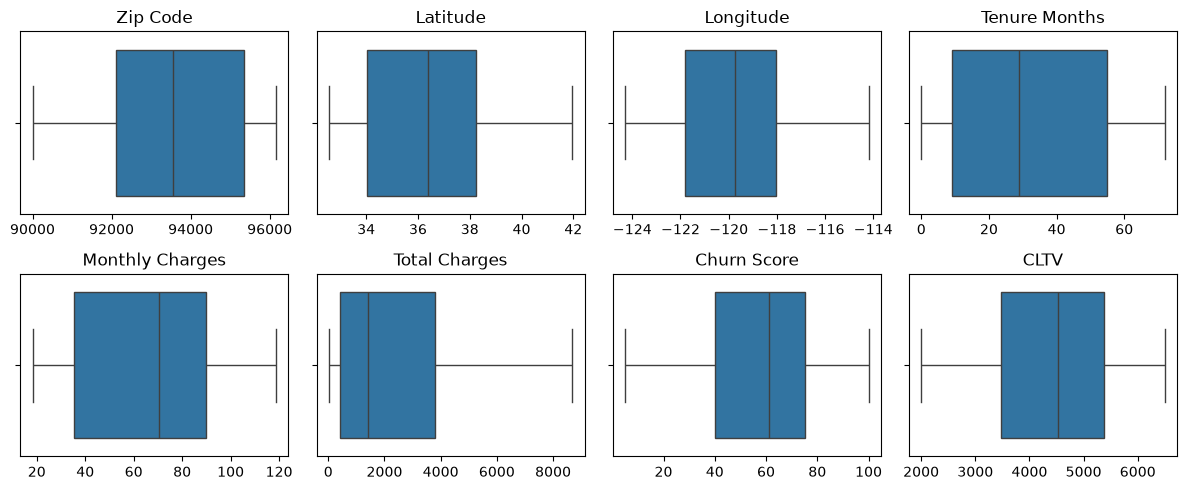

In [19]:
# Seleção de colunas numéricas para análise

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("Count")
numeric_columns.remove("Churn Value")

# Gráfico de dispersão e histograma das variáveis numéricas

n_columns = len(numeric_columns)
fig, axes = plt.subplots(n_columns, n_columns, figsize=(3 * n_columns, 2.5 * n_columns))

for row, y_column in enumerate(numeric_columns):
    for col, x_column in enumerate(numeric_columns):
        ax = axes[row, col]

        if row == col:
            ax.hist(df[x_column].dropna(), bins=30, edgecolor="black")
        else:
            pair = df[[x_column, y_column]].dropna()
            ax.scatter(pair[x_column], pair[y_column], alpha=0.3, s=8)

        if row == 0:
            ax.set_title(x_column)
        if col == 0:
            ax.set_ylabel(y_column)

plt.tight_layout()

# Matriz de correlação das variáveis numéricas

correlation_matrix = df[numeric_columns].corr()

plt.figure(
    figsize=(max(8, 1.2 * len(numeric_columns)), max(6, 1.0 * len(numeric_columns)))
)
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
)
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout()

# Boxplot das variáveis numéricas

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12, 5))

for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(x=df[column], ax=ax)
    ax.set_title(f"{column}")
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()

### Observações

Variáveis para descarte:
- CustomerID: Sem valor agregado
- Count: Sem valor agregado
- Country: Valor constante
- State: Valor constante
- Churn Label: Mesmo valor que Churn Value

Possíveis variáveis para descarte:
- City
- Zip Code
- Lat Long
As três variáveis são redundantes em relação as variáveis Latitude e Longitude.

Analisar a correlação entre as variáveis Tenure Months, Monthly Charges e Total Charges.
Total Charges = Tenure Months * Monthly Charges

O dataset é desbalanceado.

Não foram identificados outliers.

**Roteiro da Análise**

1. Integridade e Sanidade dos Dados
   * Valores ausentes
   * Cardinalidade e tipos de variáveis
2. Diagnóstico do Target (distribuição de classes)
3. Análise Univariada
   * Features numéricas
   * Features categóricas
4. Comentários